# CASALS L0 TDMS: Acquisition Metadata, Wavelength Scanning, and Raw Waveform Audit

This notebook audits one selected CASALS L0 TDMS file. It inventories file, group, and channel properties; checks the recorded Step/Sweep layout against viewer indexing; reads selected waveform rows; and reviews local L1B metadata without loading H5 waveform payloads. It does not run the production L0-to-L1B processor or infer wavelengths from channel numbers.

Evidence grades A, B, and C emit a physical wavelength map only when their complete per-channel requirements are met. Grade D covers scan indices, incomplete candidates, or absent/contradictory evidence. A 256-position layout is not evidence of 256 known wavelength values.

Run Jupyter from the CASALS repository root. `nptdms` is part of the `notebooks` extra; no GUI dependencies are needed.

## 1. Input selection and bounded run settings

Set `TDMS_PATH` to one file when the data directory contains multiple TDMS recordings. `ROW_INDICES` selects raw rows; leaving it unset samples the first, middle, and last rows. `OUTPUT_ROOT` may point to a custom destination. No synthetic data are used when source files are absent.

In [1]:
from datetime import datetime
from pathlib import Path
import json
import os
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from research.tdms_audit import (
    analyze_channel_layout,
    channel_property_variation,
    discover_tdms_files,
    metadata_inventory,
    open_tdms_metadata,
    read_waveform_row,
    scan_property_rows,
    select_row_indices,
    select_tdms_file,
    wavelength_evidence,
)

_working_directory = Path.cwd().resolve()
ROOT = next((candidate for candidate in (_working_directory, *_working_directory.parents)
             if (candidate / "pyproject.toml").is_file() and (candidate / "casals_l1b").is_dir()), None)
if ROOT is None:
    raise RuntimeError("Start Jupyter from the CASALS repository or one of its subdirectories.")

TDMS_DATA_DIR = ROOT / "data/raw/tdms"
TDMS_PATH = os.environ.get("CASALS_TDMS_PATH") or None
OUTPUT_ROOT = os.environ.get("CASALS_TDMS_OUTPUT_ROOT") or None
_rows = os.environ.get("CASALS_TDMS_ROW_INDICES")
ROW_INDICES = [int(value.strip()) for value in _rows.split(",") if value.strip()] if _rows else None
N_EXAMPLE_CHANNELS = int(os.environ.get("CASALS_TDMS_N_EXAMPLE_CHANNELS", "6"))
if N_EXAMPLE_CHANNELS < 1:
    raise ValueError("N_EXAMPLE_CHANNELS must be at least 1.")

print("TDMS_PATH:", TDMS_PATH or "unset (automatic selection is allowed only for one file)")
print("OUTPUT_ROOT:", OUTPUT_ROOT or "default: outputs/notebooks/data/tdms_audit/<tdms-stem>/runs/<timestamp>/")
print("ROW_INDICES:", ROW_INDICES or "unset (first, middle, and last)")
print("N_EXAMPLE_CHANNELS:", N_EXAMPLE_CHANNELS)

TDMS_PATH: data/raw/tdms/casals_18-11-2024_13-34-53_158-003.tdms
OUTPUT_ROOT: outputs/notebooks/data/tdms_audit/casals_18-11-2024_13-34-53_158-003/runs/20261014_wavelength_audit_05
ROW_INDICES: unset (first, middle, and last)
N_EXAMPLE_CHANNELS: 6


In [2]:
candidate_files = discover_tdms_files(TDMS_DATA_DIR)
display(pd.DataFrame([
    {"file": path.relative_to(ROOT).as_posix(), "size_bytes": path.stat().st_size,
     "size_gib": round(path.stat().st_size / 1024**3, 3)}
    for path in candidate_files
]))

TDMS_FILE = select_tdms_file(ROOT, TDMS_DATA_DIR, TDMS_PATH)
if OUTPUT_ROOT:
    OUTPUT_DIR = Path(OUTPUT_ROOT).expanduser()
    OUTPUT_DIR = OUTPUT_DIR if OUTPUT_DIR.is_absolute() else ROOT / OUTPUT_DIR
else:
    run_id = datetime.now().strftime("%Y%m%dT%H%M%S")
    OUTPUT_DIR = ROOT / "outputs/notebooks/data/tdms_audit" / TDMS_FILE.stem / "runs" / run_id
OUTPUT_DIR = OUTPUT_DIR.resolve()
if OUTPUT_DIR.exists() and any(OUTPUT_DIR.iterdir()):
    raise FileExistsError(f"Refusing to overwrite nonempty audit output directory: {OUTPUT_DIR}")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Selected input:", TDMS_FILE)
print("Output directory:", OUTPUT_DIR)

,file,size_bytes,size_gib
0,data/raw/tdms/casals_18-11-2024_13-34-53_158-0...,20300447744,18.906
1,data/raw/tdms/casals_18-11-2024_13-37-23_164-0...,17582538752,16.375


Selected input: C:\Users\zhong267\OneDrive - purdue.edu\CASALS\data\raw\tdms\casals_18-11-2024_13-34-53_158-003.tdms
Output directory: C:\Users\zhong267\OneDrive - purdue.edu\CASALS\outputs\notebooks\data\tdms_audit\casals_18-11-2024_13-34-53_158-003\runs\20261014_wavelength_audit_05


## 2. Complete metadata inventory

Metadata-only reading records raw property types and values without loading waveform arrays. The CSV is the complete property listing; the tables below provide a compact view of file structure and scan-related fields.

In [3]:
with open_tdms_metadata(TDMS_FILE) as (metadata_file, reader_info):
    inventory = metadata_inventory(metadata_file)
    inventory["reader_status"].update(reader_info)

(OUTPUT_DIR / "metadata_inventory.json").write_text(
    json.dumps(inventory, indent=2, ensure_ascii=False, allow_nan=False), encoding="utf-8"
)
property_df = pd.DataFrame(inventory["property_rows"])
if not property_df.empty:
    property_df["raw_value_json"] = property_df["raw_value"].map(
        lambda value: json.dumps(value, ensure_ascii=False, allow_nan=False)
    )
    property_df = property_df.drop(columns=["raw_value"])
property_df.to_csv(OUTPUT_DIR / "property_inventory.csv", index=False)

structure_rows = []
for group in inventory["groups"]:
    channels = group["channels"]
    structure_rows.append({
        "group": group["name"],
        "group_property_count": len(group["properties"]),
        "channel_count": len(channels),
        "channel_lengths": sorted({channel["length"] for channel in channels}),
        "data_types": sorted({channel["data_type"] for channel in channels}),
        "dtypes": sorted({channel["dtype"] for channel in channels}),
    })
display(pd.DataFrame([{
    "file_property_count": len(inventory["file_properties"]),
    "file_properties": inventory["file_properties"],
}]))
display(pd.DataFrame(structure_rows))

print("Complete file/group property inventory:")
display(property_df.loc[property_df["scope"].isin(["file", "group"]), [
    "scope", "group_name", "property_name", "raw_data_type", "raw_value_json", "unit"
]])

channel_keys = sorted({
    name for group in inventory["groups"] for channel in group["channels"]
    for name in channel["properties"]
})
print("Distinct channel property keys:", channel_keys or "none")
variation = channel_property_variation(inventory)
if variation:
    display(pd.DataFrame([
        {key: value for key, value in item.items() if key != "values_by_channel"}
        for item in variation
    ]))
    for item in variation:
        display(Markdown(f"**{item['property_name']} values by channel**"))
        display(pd.Series(item["values_by_channel"], name=item["property_name"]))
else:
    print("No channel-level properties are stored in this TDMS file.")

scan_properties = scan_property_rows(inventory["property_rows"])
print("Scan, acquisition, timing, detector, and calibration-related properties:")
if scan_properties:
    display(pd.DataFrame([{
        "scope": row["scope"], "group": row["group_name"], "channel": row["channel_name"],
        "property": row["property_name"], "raw_type": row["raw_data_type"],
        "raw_value": row["readable_value"], "unit": row["unit"],
    } for row in scan_properties]))
else:
    print("No matching scan/acquisition property names were found; the complete inventory remains in property_inventory.csv.")

,file_property_count,file_properties
0,1,{'name': 'casals_18-11-2024_13-34-53_158'}


,group,group_property_count,channel_count,channel_lengths,data_types,dtypes
0,CASALS,12,256,[39649280],[<class 'nptdms.types.Int16'>],[int16]


Complete file/group property inventory:


,scope,group_name,property_name,raw_data_type,raw_value_json,unit
0,file,NaN,name,str,"""casals_18-11-2024_13-34-53_158""",NaN
1,group,CASALS,TxWinWidth(tick),int,10,tick
2,group,CASALS,RxWinWidth(tick),int,341,tick
3,group,CASALS,# WVLSteps/Sweep,int,32,NaN
4,group,CASALS,# Sweeps/ShiftCycle,int,8,NaN
5,group,CASALS,SOAtoStartPulseDelay(tick),int,80,tick
6,group,CASALS,SOAtoMZMDelay(tick),int,14,tick
7,group,CASALS,RxADCDelay(tick),int,41,tick
8,group,CASALS,SweepToFirstSOADelay(tick),int,26,tick
9,group,CASALS,ErrorBits(U16),int,0,NaN


Distinct channel property keys: none
No channel-level properties are stored in this TDMS file.
Scan, acquisition, timing, detector, and calibration-related properties:


,scope,group,channel,property,raw_type,raw_value,unit
0,group,CASALS,None,TxWinWidth(tick),int,10,tick
1,group,CASALS,None,RxWinWidth(tick),int,341,tick
2,group,CASALS,None,# WVLSteps/Sweep,int,32,NaN
3,group,CASALS,None,# Sweeps/ShiftCycle,int,8,NaN
4,group,CASALS,None,SOAtoStartPulseDelay(tick),int,80,tick
5,group,CASALS,None,SOAtoMZMDelay(tick),int,14,tick
6,group,CASALS,None,RxADCDelay(tick),int,41,tick
7,group,CASALS,None,SweepToFirstSOADelay(tick),int,26,tick
8,group,CASALS,None,SOADelay(tick),int,0,tick
9,group,CASALS,None,Sweeps/File,int,14080,NaN


## 3. Step/Sweep channel layout and viewer indexing

The matrix below uses rows for wavelength-step indices and columns for sweep or shift-cycle positions. The viewer's candidate footprint index is `step * sweeps_per_cycle + sweep`; this describes its array ordering, not a verified physical wavelength or L1B track mapping.

group_name                                                 CASALS
steps_per_sweep                                                32
sweeps_per_cycle                                                8
footprints_per_row                                            256
rows_per_file                                               14080
expected_channel_count                                        256
actual_channel_count                                          256
recognized_channel_count                                      256
missing_step_sweep                                             []
duplicate_step_sweep                                           []
duplicate_channel_names                                        []
unrecognized_channels                                          []
extra_step_sweep                                               []
channel_order_in_file                       sweep-major then step
file_order_matches_sweep_major_then_step                     True
file_order

,name,length,data_type,dtype,group_name,file_order,sweep,step,footprint_index,layout_status,channel_property_keys
0,Sweep0Step0,39649280,<class 'nptdms.types.Int16'>,int16,CASALS,0,0,0,0,ok,
1,Sweep0Step1,39649280,<class 'nptdms.types.Int16'>,int16,CASALS,1,0,1,8,ok,
2,Sweep0Step2,39649280,<class 'nptdms.types.Int16'>,int16,CASALS,2,0,2,16,ok,
3,Sweep0Step3,39649280,<class 'nptdms.types.Int16'>,int16,CASALS,3,0,3,24,ok,
4,Sweep0Step4,39649280,<class 'nptdms.types.Int16'>,int16,CASALS,4,0,4,32,ok,
5,Sweep0Step5,39649280,<class 'nptdms.types.Int16'>,int16,CASALS,5,0,5,40,ok,
6,Sweep0Step6,39649280,<class 'nptdms.types.Int16'>,int16,CASALS,6,0,6,48,ok,
7,Sweep0Step7,39649280,<class 'nptdms.types.Int16'>,int16,CASALS,7,0,7,56,ok,
8,Sweep0Step8,39649280,<class 'nptdms.types.Int16'>,int16,CASALS,8,0,8,64,ok,
9,Sweep0Step9,39649280,<class 'nptdms.types.Int16'>,int16,CASALS,9,0,9,72,ok,


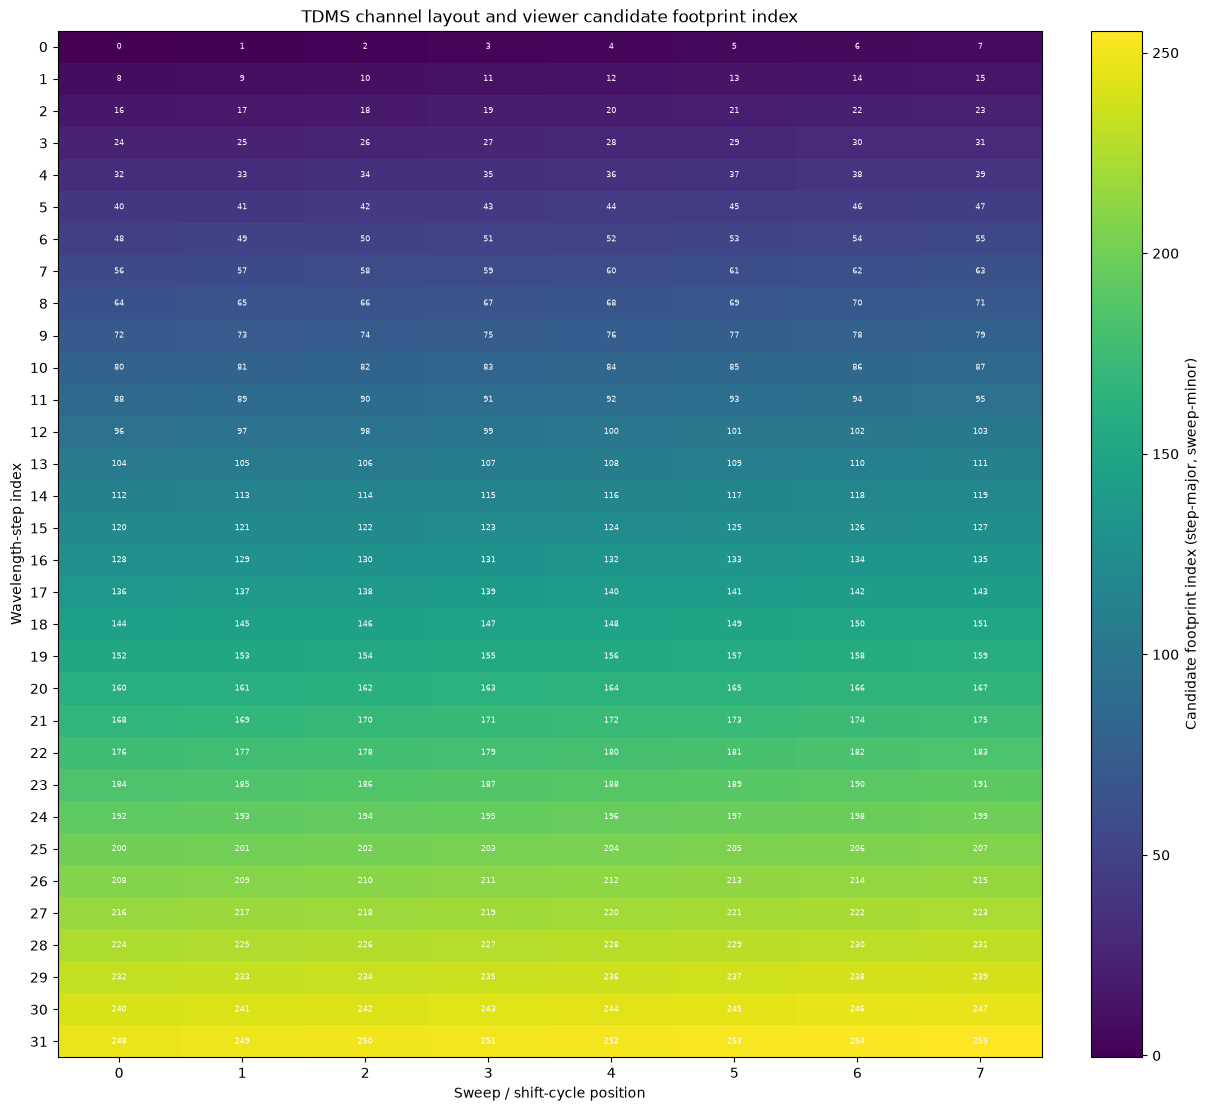

In [4]:
layout = analyze_channel_layout(inventory)
layout_rows = []
for channel in layout["channels"]:
    row = {key: value for key, value in channel.items() if key != "properties"}
    row["channel_property_keys"] = ", ".join(channel["properties"])
    layout_rows.append(row)
channel_layout_df = pd.DataFrame(layout_rows)
channel_layout_df.to_csv(OUTPUT_DIR / "channel_layout.csv", index=False)

layout_summary = {key: value for key, value in layout.items() if key != "channels"}
display(pd.Series(layout_summary, name="observed TDMS layout"))
display(channel_layout_df.head(12))

if layout["steps_per_sweep"] and layout["sweeps_per_cycle"]:
    steps = layout["steps_per_sweep"]
    sweeps = layout["sweeps_per_cycle"]
    index_grid = np.full((steps, sweeps), np.nan)
    for channel in layout["channels"]:
        if channel["footprint_index"] is not None and channel["layout_status"] == "ok":
            index_grid[channel["step"], channel["sweep"]] = channel["footprint_index"]
    fig, ax = plt.subplots(figsize=(12, 11), constrained_layout=True)
    image = ax.imshow(index_grid, origin="upper", aspect="auto", cmap="viridis",
                      vmin=-0.5, vmax=max(0.5, steps * sweeps - 0.5))
    for step in range(steps):
        for sweep in range(sweeps):
            value = index_grid[step, sweep]
            label = f"{int(value)}" if np.isfinite(value) else "missing"
            ax.text(sweep, step, label, ha="center", va="center", fontsize=5.5,
                    color="white" if np.isfinite(value) else "red")
    ax.set(xticks=np.arange(sweeps), yticks=np.arange(steps),
           xlabel="Sweep / shift-cycle position", ylabel="Wavelength-step index",
           title="TDMS channel layout and viewer candidate footprint index")
    fig.colorbar(image, ax=ax, label="Candidate footprint index (step-major, sweep-minor)")
    fig.savefig(OUTPUT_DIR / "channel_layout.png", dpi=180)
    plt.show()
    plt.close(fig)
else:
    print("A Step/Sweep layout plot is unavailable because the TDMS metadata did not declare both dimensions.")

## 4. Wavelength evidence grade

A physical wavelength plot is produced only for a complete grade A, B, or C mapping. Grade A requires unit-bearing per-channel values; B requires a complete unit-bearing lookup table with declared order; C requires unit-bearing start, step increment, sweep offset, a supported Step/Sweep formula, and explicit ShiftCycle applicability. Step numbers, scan-only values, and nominal design values never become measured wavelengths.

In [5]:
wavelength = wavelength_evidence(inventory, layout, source_file=TDMS_FILE.name)
wavelength_rows = wavelength["source_properties"]
wavelength_df = pd.DataFrame([{
    "scope": row["scope"], "group": row["group_name"], "channel": row["channel_name"],
    "property": row["property_name"], "raw_type": row["raw_data_type"],
    "raw_value_json": json.dumps(row["raw_value"], ensure_ascii=False, allow_nan=False),
    "unit": row["unit"], "evidence_grade": wavelength["grade"],
} for row in wavelength_rows])
if wavelength_df.empty:
    wavelength_df = pd.DataFrame([{
        "scope": "none", "group": None, "channel": None,
        "property": "No wavelength-related property found", "raw_type": None,
        "raw_value_json": None, "unit": None, "evidence_grade": wavelength["grade"],
    }])
wavelength_df.to_csv(OUTPUT_DIR / "wavelength_evidence.csv", index=False)
(OUTPUT_DIR / "wavelength_evidence.json").write_text(
    json.dumps(wavelength, indent=2, ensure_ascii=False, allow_nan=False), encoding="utf-8"
)

display(Markdown(f"**Evidence grade {wavelength['grade']}: {wavelength['label']}**" + chr(10) + wavelength["explanation"]))
if wavelength["source_properties"]:
    display(wavelength_df)
if wavelength["physical_wavelength_available"]:
    wavelength_map_df = pd.DataFrame(wavelength["mapping"]).sort_values("footprint_index")
    display(wavelength_map_df.head(12))
    fig, ax = plt.subplots(figsize=(12, 4.5), constrained_layout=True)
    ax.plot(wavelength_map_df["footprint_index"], wavelength_map_df["wavelength_nm"], ".-", ms=3)
    ax.set(xlabel="Viewer candidate footprint index", ylabel="Wavelength (nm)",
           title=f"Evidence-backed physical wavelength mapping (grade {wavelength['grade']})")
    fig.savefig(OUTPUT_DIR / "wavelength_vs_channel.png", dpi=180)
    plt.show()
    plt.close(fig)
else:
    print("Physical wavelength values: not available / not recoverable from inspected metadata.")
    print("Missing calibration information:", wavelength["missing_calibration_information"])

**Evidence grade D: Scan Indices Only**
Step/Sweep indices and acquisition dimensions establish channel organization only; they do not establish physical wavelengths.

,scope,group,channel,property,raw_type,raw_value_json,unit,evidence_grade
0,group,CASALS,None,# WVLSteps/Sweep,int,32,None,D


Physical wavelength values: not available / not recoverable from inspected metadata.
Missing calibration information: ['A per-channel or per-pulse physical wavelength with an explicit unit, or a 256-entry lookup table with declared order.', 'If using parameters: an explicit calibrated relationship that includes Step and Sweep, plus ShiftCycle applicability.', 'Calibration traceability or a flight-specific calibration record to independently validate the wavelength scale.']


## 5. Sampling and TX/RX assumptions

The current viewer's sample-rate and TX-cut values are treated as code parameters. Metadata fields expressed in ticks are reported as ticks; waveform shape alone cannot establish their conversion to samples, seconds, or physical range.

In [6]:
viewer_source = (ROOT / "casals_tdms_viewer/tdms_processor.py").read_text(encoding="utf-8")
viewer_sample_rate_match = re.search(r"\bfs\s*=\s*([0-9.eE+-]+)", viewer_source)
viewer_sample_rate_hz = float(viewer_sample_rate_match.group(1)) if viewer_sample_rate_match else None
from casals_tdms_viewer.tdms_processor import CasalsTdmsProcessor
viewer_defaults = CasalsTdmsProcessor()
viewer_parameters = {
    "viewer_default_wavelength_steps_per_sweep": viewer_defaults.wvl_steps_per_sweep,
    "viewer_default_sweeps_per_shift_cycle": viewer_defaults.sweeps_per_cycle,
    "viewer_tx_samples_cut": list(viewer_defaults.tx_samples_cut),
    "viewer_assumed_sample_rate_hz": viewer_sample_rate_hz,
    "viewer_source": "casals_tdms_viewer/tdms_processor.py",
}
display(pd.Series(viewer_parameters, name="existing viewer parameters"))

sample_timing_properties = [row for row in inventory["property_rows"]
                            if re.search(r"sample|sampling|frequency|interval|clock|digitizer|adc|tick|\btx\b|\brx\b",
                                         row["property_name"], re.IGNORECASE)]
if sample_timing_properties:
    display(pd.DataFrame([{
        "scope": row["scope"], "property": row["property_name"],
        "raw_value": row["readable_value"], "unit": row["unit"],
    } for row in sample_timing_properties]))

explicit_sample_rate = [row for row in sample_timing_properties
                        if re.search(r"sample.?rate|sampling.?frequency|sampling.?interval|digitizer.?frequency|adc.?frequency",
                                     row["property_name"], re.IGNORECASE)
                        and row["unit"] in {"hz", "khz", "mhz", "ghz"}]
if explicit_sample_rate:
    print("Explicit sample-rate evidence:", [(row["property_name"], row["raw_value"], row["unit"])
                                               for row in explicit_sample_rate])
else:
    print("Sampling rate assumed by existing viewer; not verified from inspected TDMS metadata.")
print("TX/RX window fields, if present, do not establish sample-index boundaries without a tick-to-sample/time calibration.")

viewer_default_wavelength_steps_per_sweep                                      32
viewer_default_sweeps_per_shift_cycle                                           8
viewer_tx_samples_cut                                                     [8, 68]
viewer_assumed_sample_rate_hz                                        1000000000.0
viewer_source                                casals_tdms_viewer/tdms_processor.py
Name: existing viewer parameters, dtype: object

,scope,property,raw_value,unit
0,group,TxWinWidth(tick),10,tick
1,group,RxWinWidth(tick),341,tick
2,group,SOAtoStartPulseDelay(tick),80,tick
3,group,SOAtoMZMDelay(tick),14,tick
4,group,RxADCDelay(tick),41,tick
5,group,SweepToFirstSOADelay(tick),26,tick
6,group,SOADelay(tick),0,tick


Sampling rate assumed by existing viewer; not verified from inspected TDMS metadata.
TX/RX window fields, if present, do not establish sample-index boundaries without a tick-to-sample/time calibration.


## 6. Bounded raw-waveform samples

Only the selected rows and their sample intervals are read with `channel[start:stop]`. These plots use raw sample index and raw counts. They do not assert sample time, distance, TX/RX alignment, or a detected physical return.

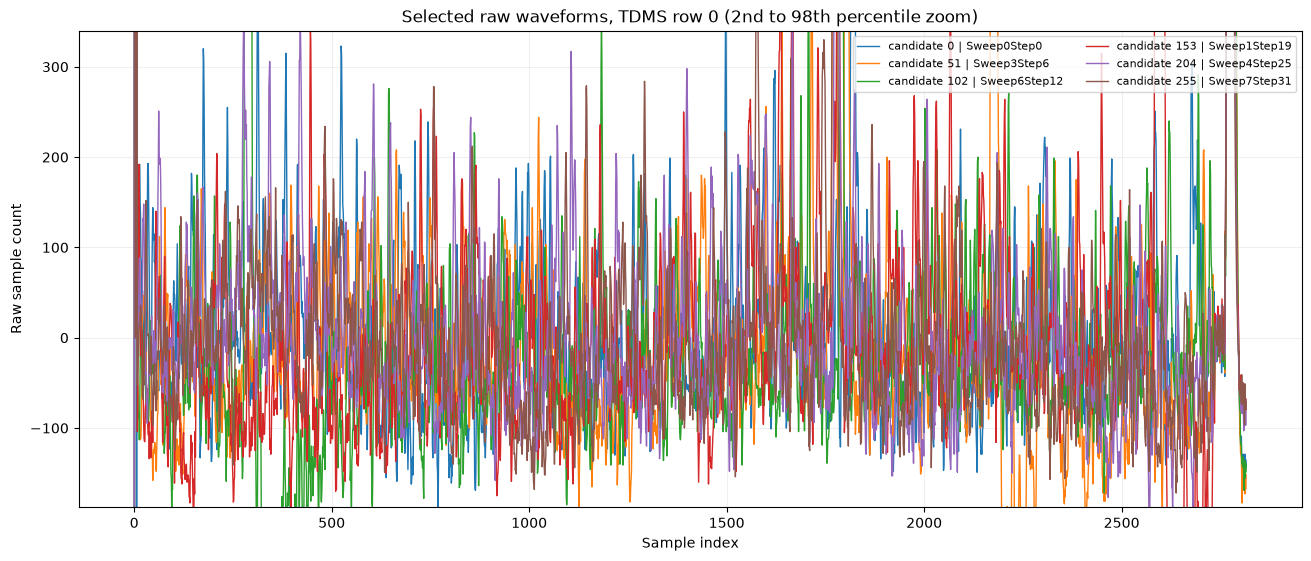

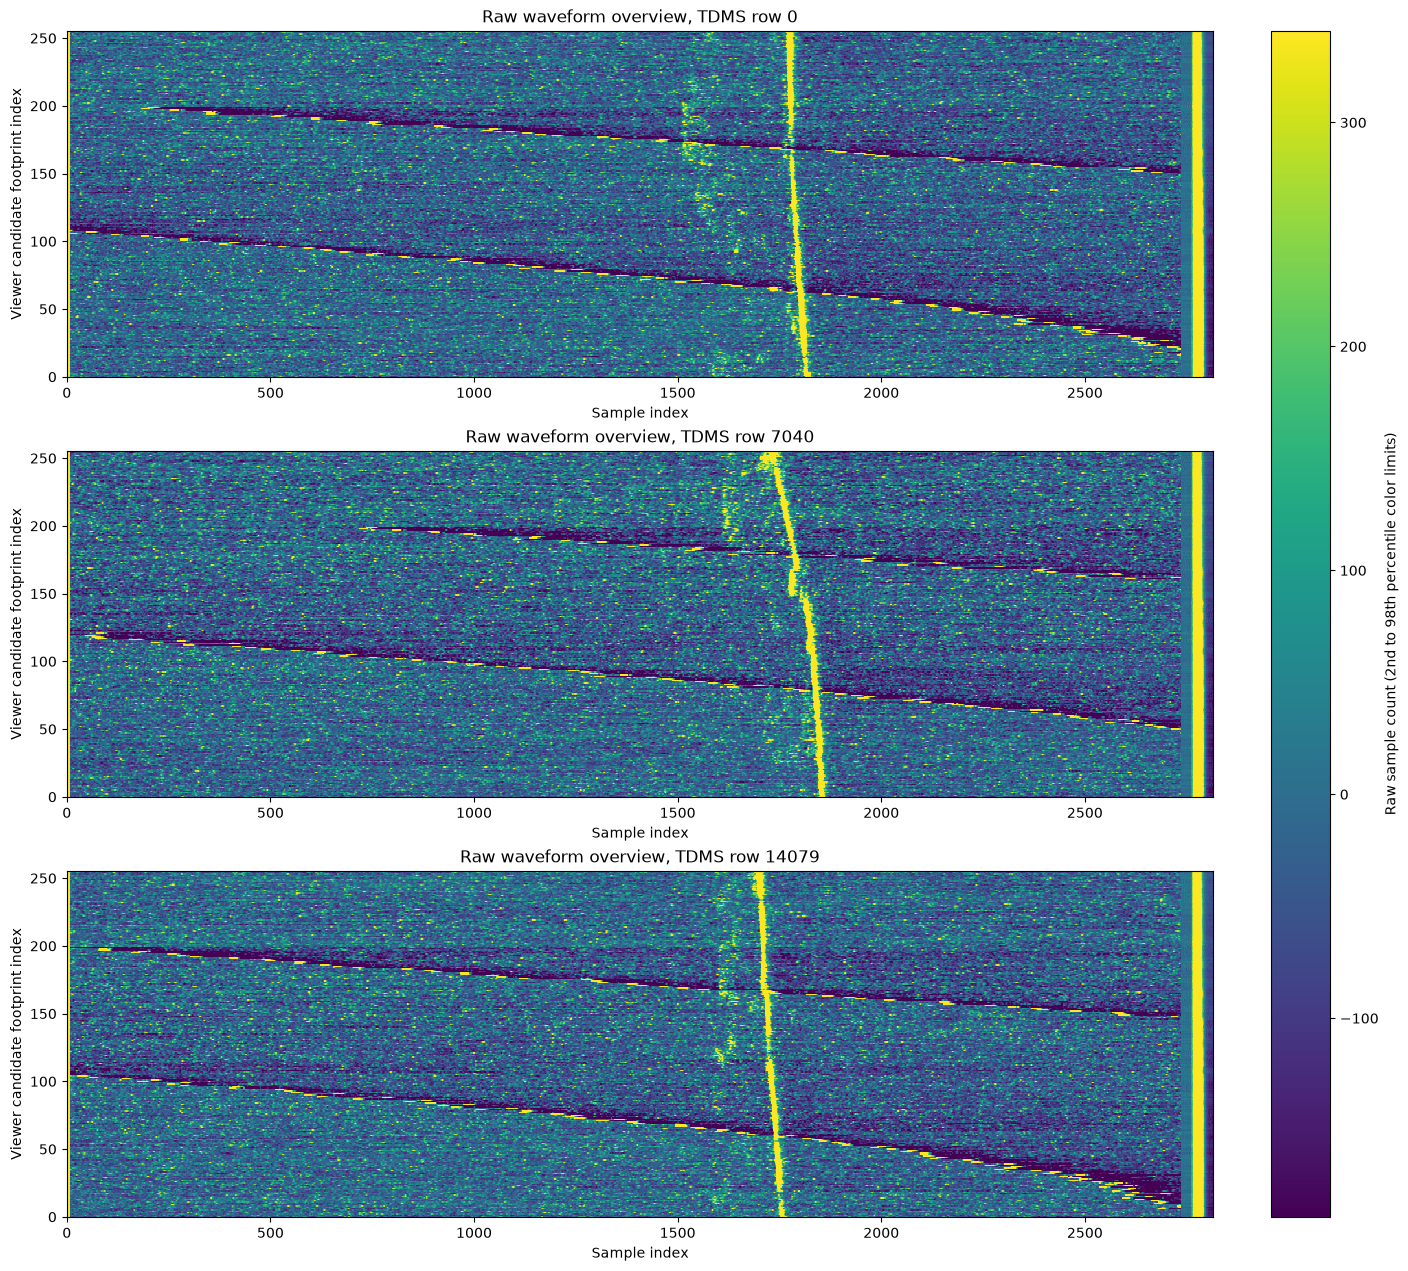

,row_index,footprint_index,channel_name,sweep,step,sample_count,minimum_raw_count,maximum_raw_count,median_raw_count,standard_deviation_raw_count,zero_fraction,max_excursion_from_median_raw_count,dtype_rail_count
73,0,73,Sweep1Step9,1,9,2816,-32655.0,19981.0,-33.0,1118.021241,0.003196,32622.0,0
195,0,195,Sweep3Step24,3,24,2816,-32622.0,19982.0,-73.0,1211.586133,0.004261,32549.0,0
187,0,187,Sweep3Step23,3,23,2816,-427.0,32313.0,-23.0,915.567052,0.007457,32336.0,0
65,0,65,Sweep1Step8,1,8,2816,-317.0,32172.0,-9.0,1058.311666,0.004261,32181.0,0
203,0,203,Sweep3Step25,3,25,2816,-32028.0,19982.0,-12.0,780.053251,0.008168,32016.0,0
81,0,81,Sweep1Step10,1,10,2816,-31951.0,19981.0,-40.5,1085.388816,0.006392,31910.5,0
179,0,179,Sweep3Step22,3,22,2816,-411.0,31704.0,-32.0,894.393989,0.005327,31736.0,0
57,0,57,Sweep1Step7,1,7,2816,-301.0,31458.0,-19.0,978.271392,0.004616,31477.0,0
211,0,211,Sweep3Step26,3,26,2816,-31442.0,19982.0,-8.0,776.540990,0.009588,31434.0,0
89,0,89,Sweep1Step11,1,11,2816,-31252.0,19981.0,-31.0,1025.625351,0.006037,31221.0,0


Selected rows read by slices; bounded-row viewer/software parity after its configured cut passed; this does not establish physical footprint order.
Sampled row indices: [0, 7040, 14079] | matrix shape: (256, 2816)
Largest sample excursion is a raw-count screening statistic, not a waveform detection.


In [7]:
selected_rows = select_row_indices(layout["rows_per_file"], ROW_INDICES) if layout["rows_per_file"] else []
waveforms_by_row = {}
waveform_stats = []
WAVEFORM_VIEWER_PARITY = None
example_footprints = []
if not layout["layout_complete"] or not layout["samples_per_row"]:
    WAVEFORM_STATUS = "Skipped: channel layout or row/sample shape is incomplete."
    print(WAVEFORM_STATUS)
else:
    n_footprints = layout["footprints_per_row"]
    n_samples = layout["samples_per_row"]
    ordered_channels = sorted(layout["channels"], key=lambda item: item["footprint_index"])
    example_footprints = np.unique(np.linspace(
        0, n_footprints - 1, min(N_EXAMPLE_CHANNELS, n_footprints), dtype=int
    )).tolist()
    with open_tdms_metadata(TDMS_FILE) as (wave_tdms, _):
        group = wave_tdms[layout["group_name"]]
        for row_index in selected_rows:
            matrix = np.empty((n_footprints, n_samples), dtype=np.dtype(ordered_channels[0]["dtype"]))
            for channel in ordered_channels:
                samples = read_waveform_row(
                    group[channel["name"]], row_index, n_samples, layout["rows_per_file"]
                )
                matrix[channel["footprint_index"], :] = samples
            waveforms_by_row[row_index] = matrix

    # Compare one bounded raw row with the existing viewer's step-major, cut-waveform output.
    viewer_processor = CasalsTdmsProcessor()
    try:
        viewer_processor.load(TDMS_FILE)
        viewer_row = viewer_processor.extract_vis_swath_row(selected_rows[0])
        head_cut, tail_cut = viewer_processor.tx_samples_cut
        cut_end = n_samples - tail_cut if tail_cut else None
        expected_viewer_row = waveforms_by_row[selected_rows[0]][:, head_cut:cut_end]
        WAVEFORM_VIEWER_PARITY = bool(np.array_equal(viewer_row, expected_viewer_row))
    finally:
        viewer_processor.close()
    if not WAVEFORM_VIEWER_PARITY:
        raise AssertionError("Selected TDMS row does not match the current viewer's step-major output after its configured cut.")
    WAVEFORM_STATUS = "Selected rows read by slices; bounded-row viewer/software parity after its configured cut passed; this does not establish physical footprint order."

    for row_index, matrix in waveforms_by_row.items():
        integer_limits = np.iinfo(matrix.dtype) if np.issubdtype(matrix.dtype, np.integer) else None
        for channel in ordered_channels:
            values = matrix[channel["footprint_index"]].astype(np.float64)
            median = float(np.median(values))
            stats = {
                "row_index": row_index,
                "footprint_index": channel["footprint_index"],
                "channel_name": channel["name"],
                "sweep": channel["sweep"],
                "step": channel["step"],
                "sample_count": int(values.size),
                "minimum_raw_count": float(np.min(values)),
                "maximum_raw_count": float(np.max(values)),
                "median_raw_count": median,
                "standard_deviation_raw_count": float(np.std(values)),
                "zero_fraction": float(np.mean(values == 0)),
                "max_excursion_from_median_raw_count": float(np.max(np.abs(values - median))),
                "dtype_rail_count": int(np.count_nonzero((values == integer_limits.min) | (values == integer_limits.max)))
                    if integer_limits is not None else None,
            }
            waveform_stats.append(stats)
    waveform_stats_df = pd.DataFrame(waveform_stats)
    waveform_stats_df.to_csv(OUTPUT_DIR / "waveform_sample_statistics.csv", index=False)

    example_row = selected_rows[0]
    example_matrix = waveforms_by_row[example_row]
    fig, ax = plt.subplots(figsize=(13, 5.5), constrained_layout=True)
    for footprint in example_footprints:
        channel = ordered_channels[footprint]
        ax.plot(np.arange(n_samples), example_matrix[footprint], lw=1.0,
                label=f"candidate {footprint} | {channel['name']}")
    ax.set(xlabel="Sample index", ylabel="Raw sample count",
           title=f"Selected raw waveforms, TDMS row {example_row}")
    ax.grid(True, alpha=0.2)
    ax.legend(ncol=2, fontsize=8)
    fig.savefig(OUTPUT_DIR / "waveform_examples.png", dpi=180)
    example_low, example_high = np.quantile(example_matrix.astype(np.float64), [0.02, 0.98])
    if example_low == example_high:
        example_high = example_low + 1.0
    ax.set_ylim(example_low, example_high)
    ax.set_title(f"Selected raw waveforms, TDMS row {example_row} (2nd to 98th percentile zoom)")
    fig.savefig(OUTPUT_DIR / "waveform_examples_zoom.png", dpi=180)
    plt.show()
    plt.close(fig)

    all_values = np.concatenate([matrix.ravel() for matrix in waveforms_by_row.values()]).astype(np.float64)
    color_low, color_high = np.quantile(all_values, [0.02, 0.98])
    if color_low == color_high:
        color_high = color_low + 1.0
    fig, axes = plt.subplots(len(selected_rows), 1, figsize=(14, 4.2 * len(selected_rows)),
                             squeeze=False, constrained_layout=True)
    for ax, row_index in zip(axes[:, 0], selected_rows):
        image = ax.imshow(waveforms_by_row[row_index], origin="lower", aspect="auto",
                          interpolation="nearest", cmap="viridis", vmin=color_low, vmax=color_high)
        ax.set(xlabel="Sample index", ylabel="Viewer candidate footprint index",
               title=f"Raw waveform overview, TDMS row {row_index}")
    fig.colorbar(image, ax=axes[:, 0].tolist(), label="Raw sample count (2nd to 98th percentile color limits)")
    fig.savefig(OUTPUT_DIR / "waveform_overview.png", dpi=180)
    plt.show()
    plt.close(fig)

    display(waveform_stats_df.loc[waveform_stats_df["row_index"] == example_row].sort_values(
        "max_excursion_from_median_raw_count", ascending=False
    ).head(10))
    print(WAVEFORM_STATUS)
    print("Sampled row indices:", selected_rows, "| matrix shape:", example_matrix.shape)
    print("Largest sample excursion is a raw-count screening statistic, not a waveform detection.")

## Bounded raw-byte and channel-read verification

The audit below checks a small set of complete TDMS storage chunks, plus a partial final chunk when present. It compares indexed channel slices, a raw-only `nptdms` reader, and values decoded directly from the raw file bytes. A storage chunk is treated as an acquisition row only when the file properties and channel lengths independently support that row layout. Selected values validate those reads; they do not certify every sample or acquisition event in the file.


In [ ]:
from research.tdms_audit import audit_raw_data_samples, summarize_raw_waveform_samples

if ROW_INDICES is not None and not layout.get("row_layout_valid"):
    raise ValueError("ROW_INDICES cannot be applied because the TDMS row layout is unresolved.")
with open_tdms_metadata(TDMS_FILE) as (raw_tdms, _):
    raw_integrity = audit_raw_data_samples(
        raw_tdms, TDMS_FILE, layout,
        ROW_INDICES if layout.get("row_layout_valid") else None,
    )
raw_waveform_summary = summarize_raw_waveform_samples(raw_integrity)
raw_integrity_export = {
    key: value for key, value in raw_integrity.items()
    if key not in {"sample_matrices", "partial_final_chunk_matrix", "layout_channels"}
}
raw_waveform_export = {
    key: value for key, value in raw_waveform_summary.items()
    if key not in {"matrices", "partial_final_chunk_matrix"}
}
(OUTPUT_DIR / "raw_integrity.json").write_text(
    json.dumps(raw_integrity_export, indent=2, ensure_ascii=False, allow_nan=False, default=str), encoding="utf-8"
)
(OUTPUT_DIR / "raw_waveform_sample_summary.json").write_text(
    json.dumps(raw_waveform_export, indent=2, ensure_ascii=False, allow_nan=False, default=str), encoding="utf-8"
)
raw_channel_statistics = pd.DataFrame(raw_waveform_summary.get("channel_statistics", []))
raw_channel_statistics.to_csv(OUTPUT_DIR / "raw_channel_sample_statistics.csv", index=False)

display(pd.Series(raw_integrity_export, name="bounded TDMS raw-integrity check"))
if raw_integrity.get("error"):
    print("Raw integrity limitation:", raw_integrity["error"])
if raw_integrity.get("sample_matrices") and layout.get("channel_structure_complete"):
    chunk_indices = sorted(raw_integrity["sample_matrices"])
    example_chunk_index = chunk_indices[0]
    example_matrix = raw_integrity["sample_matrices"][example_chunk_index]
    raw_channels = sorted(layout["channels"], key=lambda item: item["footprint_index"])
    raw_examples = np.unique(np.linspace(
        0, len(raw_channels) - 1, min(N_EXAMPLE_CHANNELS, len(raw_channels)), dtype=int
    )).tolist()
    title_unit = (
        f"TDMS row {example_chunk_index}"
        if layout.get("row_layout_valid") and layout.get("samples_per_row") == raw_integrity.get("raw_chunk_samples_per_channel")
        else f"storage chunk {example_chunk_index} (not established as an acquisition row)"
    )
    fig, ax = plt.subplots(figsize=(13, 5.5), constrained_layout=True)
    for footprint in raw_examples:
        channel = raw_channels[footprint]
        ax.plot(np.arange(example_matrix.shape[1]), example_matrix[footprint], lw=1.0,
                label=f"candidate {footprint} | {channel['name']}")
    ax.set(xlabel="Sample index within selected raw chunk", ylabel="Raw sample count",
           title=f"Raw-byte-verified waveform examples, {title_unit}")
    ax.grid(True, alpha=0.2)
    ax.legend(ncol=2, fontsize=8)
    fig.savefig(OUTPUT_DIR / "raw_chunk_waveform_examples.png", dpi=180)
    plt.show()
    plt.close(fig)

    matrices = [raw_integrity["sample_matrices"][index] for index in chunk_indices]
    tail_matrix = raw_integrity.get("partial_final_chunk_matrix")
    plot_matrices = matrices[:1] + ([tail_matrix] if tail_matrix is not None else [])
    plot_labels = [title_unit] + (["partial final storage chunk"] if tail_matrix is not None else [])
    plot_values = np.concatenate([matrix.ravel() for matrix in plot_matrices]).astype(np.float64)
    color_low, color_high = np.quantile(plot_values, [0.02, 0.98])
    if color_low == color_high:
        color_high = color_low + 1.0
    fig, axes = plt.subplots(len(plot_matrices), 1, figsize=(14, 4.2 * len(plot_matrices)),
                             squeeze=False, constrained_layout=True)
    for ax, matrix, label in zip(axes[:, 0], plot_matrices, plot_labels):
        image = ax.imshow(matrix, origin="lower", aspect="auto", interpolation="nearest",
                          cmap="viridis", vmin=color_low, vmax=color_high)
        ax.set(xlabel="Sample index within raw storage chunk",
               ylabel="Viewer candidate footprint index", title=f"Raw waveform overview: {label}")
    fig.colorbar(image, ax=axes[:, 0].tolist(), label="Raw sample count (2nd to 98th percentile color limits)")
    fig.savefig(OUTPUT_DIR / "raw_chunk_waveform_overview.png", dpi=180)
    plt.show()
    plt.close(fig)

print("Bounded raw read status:", raw_integrity["status"])
print("Selected storage chunks:", raw_integrity["sampled_chunk_indices"])
print("Selected raw values compared:", raw_integrity["sampled_value_count_checked"])
print("Structurally complete acquisition rows:", raw_integrity.get("valid_prefix_rows"))


## 7. How L0 relates to L1B

L0 stores raw waveform channels named by Step and Sweep. The viewer arranges them into a candidate footprint axis. L1B exposes geolocated sweep/track records, split `tx_waveform` and `rx_waveform` arrays, and beam geometry. Establishing a correspondence requires source provenance and a verified reshape/order convention; equal counts such as 256 channels or tracks are insufficient.

The next cells scan every local L1B object's attributes, dataset names, shapes, and dtypes, then read only `/dac`, pulse indices, timing, beam-angle, and instrument-position arrays for descriptive statistics. They compare TDMS and L1A filenames recorded in each L1B root against local files. Local L1A data are reported as `unavailable / not inspected` when no L1A H5 is present. The unannotated `/dac` dataset is summarized against recorded indices and navigation fields, but it is not interpreted as wavelength or linked to a local TDMS file.

In [8]:
import h5py
import zipfile

H5_SEARCH_TERMS = ("wavelength", "lambda", "frequency", "laser", "tuning", "steer",
                   "calibration", "shift", "track", "sweep", "dac", "step")
L1B_DIR = ROOT / "data/raw/casals_l1b"
L1B_FILES = sorted(L1B_DIR.glob("*.h5"))
LOCAL_TDMS_NAMES = {path.name for path in discover_tdms_files(TDMS_DATA_DIR)}
LOCAL_L1A_FILES = sorted((ROOT / "data/raw").rglob("*l1a*.h5"))
L1A_STATUS = "available" if LOCAL_L1A_FILES else "unavailable / not inspected"


def h5_jsonable(value):
    if isinstance(value, h5py.Reference):
        return "<HDF5 object reference>"
    if isinstance(value, bytes):
        return value.decode("utf-8", errors="replace")
    if isinstance(value, np.ndarray):
        return [h5_jsonable(item) for item in value.tolist()]
    if isinstance(value, np.generic):
        return h5_jsonable(value.item())
    if isinstance(value, (list, tuple)):
        return [h5_jsonable(item) for item in value]
    if value is None or isinstance(value, (str, int, float, bool)):
        return value
    return str(value)


def audit_l1b_metadata(h5_path):
    objects = []
    candidates = []
    with h5py.File(h5_path, "r") as h5:
        def visit(name, obj):
            object_path = "/" + name if name else "/"
            attrs = {str(key): h5_jsonable(value) for key, value in obj.attrs.items()}
            is_dataset = isinstance(obj, h5py.Dataset)
            record = {"path": object_path, "object_type": "dataset" if is_dataset else "group",
                      "attributes": attrs}
            if is_dataset:
                record.update({"shape": list(obj.shape), "dtype": str(obj.dtype)})
            objects.append(record)
            if any(term in object_path.lower() for term in H5_SEARCH_TERMS):
                candidates.append({key: record[key] for key in ("path", "object_type", "shape", "dtype", "attributes") if key in record})
            for key, value in attrs.items():
                if any(term in key.lower() or term in str(value).lower() for term in H5_SEARCH_TERMS):
                    candidates.append({"path": object_path, "attribute": key, "value": value})
        visit("", h5)
        h5.visititems(visit)
        root_attrs = {str(key): h5_jsonable(value) for key, value in h5.attrs.items()}
    tdms_reference = root_attrs.get("tdms_file")
    l1a_reference = root_attrs.get("l1a_file")
    return {
        "file_name": h5_path.name,
        "size_bytes": h5_path.stat().st_size,
        "root_attributes": root_attrs,
        "object_count": len(objects),
        "objects": objects,
        "metadata_candidates": candidates,
        "tdms_reference": tdms_reference,
        "tdms_reference_local_match": tdms_reference in LOCAL_TDMS_NAMES,
        "l1a_reference": l1a_reference,
        "l1a_reference_local_match": any(p.name == l1a_reference for p in LOCAL_L1A_FILES),
    }


def inspect_viewer_config(path):
    path = Path(path)
    if not path.is_file():
        return {"path": path.as_posix(), "available": False, "candidate_lines": []}
    terms = re.compile(r"wvl|wavelength|lambda|laser|tuning|calibr|step|sweep|shift", re.IGNORECASE)
    candidate_lines = [
        {"line_number": line_number, "text": line.strip()}
        for line_number, line in enumerate(path.read_text(encoding="utf-8", errors="replace").splitlines(), 1)
        if terms.search(line)
    ]
    return {"path": path.relative_to(ROOT).as_posix(), "available": True,
            "size_bytes": path.stat().st_size, "candidate_lines": candidate_lines}


VIEWER_PARAMETER_FILE = TDMS_DATA_DIR / "CASALS_viewer_parameter.txt"
VIEWER_INI_FILE = TDMS_DATA_DIR / "CASALS TDMS data viewer_2D average v2" / "CASALS TDMS data viewer_2D average v2.ini"
VIEWER_ARCHIVE = TDMS_DATA_DIR / "CASALS TDMS data viewer_2D average exe v2.zip"
viewer_parameter_evidence = inspect_viewer_config(VIEWER_PARAMETER_FILE)
viewer_ini_evidence = inspect_viewer_config(VIEWER_INI_FILE)
try:
    with zipfile.ZipFile(VIEWER_ARCHIVE) as archive:
        viewer_archive_evidence = {"path": VIEWER_ARCHIVE.relative_to(ROOT).as_posix(),
                                   "zip_entries": archive.namelist(),
                                   "archive_contents_executed_or_extracted": False}
except (OSError, zipfile.BadZipFile) as exc:
    viewer_archive_evidence = {"path": VIEWER_ARCHIVE.relative_to(ROOT).as_posix(),
                               "error": f"{type(exc).__name__}: {exc}"}
viewer_configuration_evidence = {
    "parameter_file": viewer_parameter_evidence,
    "ini_file": viewer_ini_evidence,
    "archive": viewer_archive_evidence,
    "interpretation": "Viewer channel selectors and defaults are not per-channel physical wavelength calibration. These files are not used to create a wavelength map.",
}

l1b_records = [audit_l1b_metadata(path) for path in L1B_FILES]
cross_level_evidence = {
    "l1a_status": L1A_STATUS,
    "local_l1a_files": [path.name for path in LOCAL_L1A_FILES],
    "local_tdms_files": sorted(LOCAL_TDMS_NAMES),
    "l1b_file_count": len(l1b_records),
    "l1b_files": l1b_records,
    "viewer_configuration": viewer_configuration_evidence,
    "metadata_dataset_payloads_read": False,
    "interpretation": "This inventory reads HDF5 attributes, object names, shapes, and dtypes only. A later cell reads /dac and selected index/navigation datasets for descriptive summaries; no waveform arrays are loaded.",
}
(OUTPUT_DIR / "cross_level_evidence.json").write_text(
    json.dumps(cross_level_evidence, indent=2, ensure_ascii=False, allow_nan=False, default=str), encoding="utf-8"
)

cross_level_rows = [{
    "l1b_file": row["file_name"], "tdms_reference": row["tdms_reference"],
    "tdms_reference_local_match": row["tdms_reference_local_match"],
    "l1a_reference": row["l1a_reference"], "l1a_reference_local_match": row["l1a_reference_local_match"],
    "object_count": row["object_count"], "metadata_candidate_count": len(row["metadata_candidates"]),
} for row in l1b_records]
display(pd.DataFrame(cross_level_rows))
print("L1A status:", L1A_STATUS)
print("Dataset payloads read by metadata inventory:", cross_level_evidence["metadata_dataset_payloads_read"])
print("Viewer parameter candidates:")
display(pd.DataFrame(viewer_parameter_evidence["candidate_lines"]))
print("Viewer INI candidates:")
display(pd.DataFrame(viewer_ini_evidence["candidate_lines"]))
print("Viewer archive entries:", viewer_archive_evidence.get("zip_entries", viewer_archive_evidence.get("error")))
for record in l1b_records:
    print("Metadata candidates in", record["file_name"])
    display(pd.DataFrame(record["metadata_candidates"]))


,l1b_file,tdms_reference,tdms_reference_local_match,l1a_reference,l1a_reference_local_match,object_count,metadata_candidate_count
0,casals_l1b_20241112T165718_001_02.h5,casals_12-11-2024_11-58-21_22.tdms,False,casals_l1a_20241112T165718_001_01.h5,False,69,7
1,casals_l1b_20241118T171757_001_02.h5,casals_18-11-2024_12-18-37_136.tdms,False,casals_l1a_20241118T171757_001_02.h5,False,69,7


L1A status: unavailable / not inspected
L1B payloads read: False
Viewer parameter candidates:


,line_number,text
0,7,WVLSteps/Sweep = 0
1,8,Sweeps/ShiftCycle = 0
2,16,SweepToFirstSOADelay(tick) = 0
3,22,SweepCycles/File = 0
4,24,Sweeps/Frame = 0
5,28,Start Wavelength Ch = 0
6,30,End Wavelength Ch = 255
7,79,FirstPulseInShiftCycle?：True（绿灯）


Viewer INI candidates:


""


Viewer archive entries: ['CASALS TDMS data viewer_2D average v2/CASALS TDMS data viewer_2D average v2.aliases', 'CASALS TDMS data viewer_2D average v2/CASALS TDMS data viewer_2D average v2.exe', 'CASALS TDMS data viewer_2D average v2/CASALS TDMS data viewer_2D average v2.ini']
Metadata candidates in casals_l1b_20241112T165718_001_02.h5


,path,attribute,value,object_type,shape,dtype,attributes
0,/,n_sweeps,14080.0,NaN,NaN,NaN,NaN
1,/,n_tracks,256.0,NaN,NaN,NaN,NaN
2,/dac,NaN,NaN,dataset,[3604480],float64,{'DIMENSION_LIST': [['<HDF5 object reference>']]}
3,/sweep_num,NaN,NaN,dataset,[3604480],int64,{'DIMENSION_LIST': [['<HDF5 object reference>']]}
4,/sweeps,NaN,NaN,dataset,[14080],int64,{}
5,/track_num,NaN,NaN,dataset,[3604480],int64,{'DIMENSION_LIST': [['<HDF5 object reference>']]}
6,/tracks,NaN,NaN,dataset,[256],int64,{}


Metadata candidates in casals_l1b_20241118T171757_001_02.h5


,path,attribute,value,object_type,shape,dtype,attributes
0,/,n_sweeps,14080.0,NaN,NaN,NaN,NaN
1,/,n_tracks,256.0,NaN,NaN,NaN,NaN
2,/dac,NaN,NaN,dataset,[3604480],float64,{'DIMENSION_LIST': [['<HDF5 object reference>']]}
3,/sweep_num,NaN,NaN,dataset,[3604480],int64,{'DIMENSION_LIST': [['<HDF5 object reference>']]}
4,/sweeps,NaN,NaN,dataset,[14080],int64,{}
5,/track_num,NaN,NaN,dataset,[3604480],int64,{'DIMENSION_LIST': [['<HDF5 object reference>']]}
6,/tracks,NaN,NaN,dataset,[256],int64,{}


## Quantitative L1B `/dac` screening

The next cell reads `/dac` and the pulse-index, timing, beam-angle, and instrument-position datasets as numeric arrays from each local L1B H5. It summarizes their association with stored sweep/track order. The HDF5 files contain no local TDMS basename match, and `/dac` has no wavelength unit or calibration attribute; the full H5 files and waveform datasets are not loaded. These descriptive results do not establish an L0-to-L1B pairing or convert DAC values to wavelength.


In [ ]:
DAC_ASSOCIATED_DATASETS = (
    "/track_num", "/sweep_num", "/delta_time", "/local_beam_azimuth",
    "/local_beam_elevation", "/instrument_longitude", "/instrument_latitude",
)

def _pearson_r(left, right):
    left = np.asarray(left, dtype=np.float64)
    right = np.asarray(right, dtype=np.float64)
    valid = np.isfinite(left) & np.isfinite(right)
    if valid.sum() < 2:
        return None
    x = left[valid]
    y = right[valid]
    x = x - x.mean()
    y = y - y.mean()
    denominator = np.sqrt(np.dot(x, x) * np.dot(y, y))
    return float(np.dot(x, y) / denominator) if denominator else None


def analyze_l1b_dac(h5_path):
    with h5py.File(h5_path, "r") as h5:
        if "/dac" not in h5:
            return {"file_name": h5_path.name, "status": "dac_dataset_missing"}, None
        dac_dataset = h5["/dac"]
        dac = np.asarray(dac_dataset[...], dtype=np.float64)
        dac_attributes = {str(key): h5_jsonable(value) for key, value in dac_dataset.attrs.items()}
        arrays = {name: np.asarray(h5[name][...]) for name in DAC_ASSOCIATED_DATASETS if name in h5}
        n_tracks = int(h5.attrs.get("n_tracks", int(np.max(arrays["/track_num"])) + 1))
        n_sweeps = int(h5.attrs.get("n_sweeps", int(np.max(arrays["/sweep_num"])) + 1))
        root_reference = h5_jsonable(h5.attrs.get("tdms_file"))

    lengths = {"/dac": int(dac.size), **{name: int(values.size) for name, values in arrays.items()}}
    same_length = all(length == dac.size for length in lengths.values())
    if not same_length or not np.isfinite(dac).all():
        return {
            "file_name": h5_path.name, "status": "array_length_or_finite_check_failed",
            "dataset_lengths": lengths, "dac_attributes": dac_attributes,
            "tdms_reference": root_reference,
        }, None

    track = np.asarray(arrays["/track_num"], dtype=np.int64)
    sweep = np.asarray(arrays["/sweep_num"], dtype=np.int64)
    if np.any(track < 0) or np.any(sweep < 0) or np.any(track >= n_tracks) or np.any(sweep >= n_sweeps):
        return {
            "file_name": h5_path.name, "status": "index_range_check_failed",
            "dataset_lengths": lengths, "dac_attributes": dac_attributes,
            "tdms_reference": root_reference,
        }, None

    track_counts = np.bincount(track, minlength=n_tracks)
    sweep_counts = np.bincount(sweep, minlength=n_sweeps)
    pair_counts = np.bincount(track * n_sweeps + sweep, minlength=n_tracks * n_sweeps)
    track_sums = np.bincount(track, weights=dac, minlength=n_tracks)
    track_sumsq = np.bincount(track, weights=dac * dac, minlength=n_tracks)
    sweep_sums = np.bincount(sweep, weights=dac, minlength=n_sweeps)
    sweep_sumsq = np.bincount(sweep, weights=dac * dac, minlength=n_sweeps)
    track_means = track_sums / track_counts
    sweep_means = sweep_sums / sweep_counts
    track_std = np.sqrt(np.maximum(0.0, track_sumsq / track_counts - track_means * track_means))
    sweep_std = np.sqrt(np.maximum(0.0, sweep_sumsq / sweep_counts - sweep_means * sweep_means))
    unique_dac = np.unique(dac)
    positive_steps = np.diff(unique_dac)
    positive_steps = positive_steps[positive_steps > 0]
    sweep_axis = np.arange(n_sweeps, dtype=np.float64)
    slope, intercept = np.polyfit(sweep_axis, sweep_means, 1)
    fitted = intercept + slope * sweep_axis
    residual_sum = float(np.sum((sweep_means - fitted) ** 2))
    total_sum = float(np.sum((sweep_means - sweep_means.mean()) ** 2))
    correlation_fields = {
        "track_num": track,
        "sweep_num": sweep,
        "delta_time": arrays.get("/delta_time"),
        "local_beam_azimuth": arrays.get("/local_beam_azimuth"),
        "local_beam_elevation": arrays.get("/local_beam_elevation"),
        "instrument_longitude": arrays.get("/instrument_longitude"),
        "instrument_latitude": arrays.get("/instrument_latitude"),
    }
    correlations = {
        name: _pearson_r(dac, values) if values is not None else None
        for name, values in correlation_fields.items()
    }
    delta_time = arrays.get("/delta_time")
    report = {
        "file_name": h5_path.name,
        "status": "summarized",
        "tdms_reference": root_reference,
        "tdms_reference_local_match": root_reference in LOCAL_TDMS_NAMES,
        "dataset_lengths": lengths,
        "n_tracks": n_tracks,
        "n_sweeps": n_sweeps,
        "all_values_finite": True,
        "dac_attributes": dac_attributes,
        "dac_unit_or_wavelength_calibration_present": any(
            re.search(r"unit|wavelength|lambda|nm|frequency|calibration", key + str(value), re.IGNORECASE)
            for key, value in dac_attributes.items()
        ),
        "dac_minimum": float(np.min(dac)),
        "dac_median": float(np.median(dac)),
        "dac_maximum": float(np.max(dac)),
        "dac_zero_count": int(np.count_nonzero(dac == 0)),
        "dac_unique_count": int(unique_dac.size),
        "dac_unique_fraction": float(unique_dac.size / dac.size),
        "dac_exact_float32_round_trip": bool(np.array_equal(dac, dac.astype(np.float32).astype(np.float64))),
        "positive_unique_dac_step_median": float(np.median(positive_steps)) if positive_steps.size else None,
        "positive_unique_dac_step_p95": float(np.quantile(positive_steps, 0.95)) if positive_steps.size else None,
        "positive_unique_dac_step_maximum": float(np.max(positive_steps)) if positive_steps.size else None,
        "track_count_minimum": int(np.min(track_counts)),
        "track_count_maximum": int(np.max(track_counts)),
        "sweep_count_minimum": int(np.min(sweep_counts)),
        "sweep_count_maximum": int(np.max(sweep_counts)),
        "track_sweep_pair_count_minimum": int(np.min(pair_counts)),
        "track_sweep_pair_count_maximum": int(np.max(pair_counts)),
        "track_sweep_pairs_with_one_record": int(np.count_nonzero(pair_counts == 1)),
        "track_order_prefix": track[:16].tolist(),
        "sweep_order_prefix": sweep[:16].tolist(),
        "delta_time_strictly_increasing": bool(np.all(np.diff(delta_time) > 0)) if delta_time is not None else None,
        "track_mean_range": [float(np.min(track_means)), float(np.max(track_means))],
        "within_track_std_min_median_max": [float(np.min(track_std)), float(np.median(track_std)), float(np.max(track_std))],
        "sweep_mean_range": [float(np.min(sweep_means)), float(np.max(sweep_means))],
        "within_sweep_std_min_median_max": [float(np.min(sweep_std)), float(np.median(sweep_std)), float(np.max(sweep_std))],
        "linear_sweep_mean_slope_per_sweep": float(slope),
        "linear_sweep_mean_r_squared": float(1 - residual_sum / total_sum) if total_sum else None,
        "increasing_sweep_mean_step_fraction": float(np.mean(np.diff(sweep_means) > 0)),
        "pearson_r_dac_vs_fields": correlations,
        "interpretation": (
            "Descriptive association only. /dac is unitless in the inspected HDF5 metadata; it is not converted to wavelength. "
            "The TDMS reference does not exactly match a local TDMS basename, so no L0-to-L1B association is inferred."
        ),
    }
    profile = {"sweep_means": sweep_means, "track_means": track_means}
    return report, profile


dac_reports = []
dac_profiles = []
for h5_path in L1B_FILES:
    report, profile = analyze_l1b_dac(h5_path)
    dac_reports.append(report)
    dac_profiles.append(profile)

dac_analysis = {
    "status": "summarized" if all(item["status"] == "summarized" for item in dac_reports) else "partial",
    "datasets_read": ["/dac", *DAC_ASSOCIATED_DATASETS],
    "full_h5_file_or_waveform_datasets_loaded": False,
    "targeted_numeric_dataset_arrays_read_in_full": True,
    "purpose": "Descriptive /dac association with recorded pulse indices and navigation fields; not a wavelength calibration.",
    "l0_tdms_pairing_verified": False,
    "files": dac_reports,
}
(OUTPUT_DIR / "dac_analysis.json").write_text(
    json.dumps(dac_analysis, indent=2, ensure_ascii=False, allow_nan=False, default=str), encoding="utf-8"
)
pd.DataFrame([{
    "file_name": row["file_name"], "status": row["status"],
    "dac_minimum": row.get("dac_minimum"), "dac_median": row.get("dac_median"),
    "dac_maximum": row.get("dac_maximum"), "dac_unique_count": row.get("dac_unique_count"),
    "track_sweep_pairs_with_one_record": row.get("track_sweep_pairs_with_one_record"),
    "linear_sweep_mean_slope_per_sweep": row.get("linear_sweep_mean_slope_per_sweep"),
    "linear_sweep_mean_r_squared": row.get("linear_sweep_mean_r_squared"),
    **{f"pearson_r_{name}": value for name, value in row.get("pearson_r_dac_vs_fields", {}).items()},
} for row in dac_reports]).to_csv(OUTPUT_DIR / "dac_analysis.csv", index=False)

fig, axes = plt.subplots(len(dac_reports), 2, figsize=(14, max(4.5, 4.1 * len(dac_reports))),
                         squeeze=False, constrained_layout=True)
for row_index, (report, profile) in enumerate(zip(dac_reports, dac_profiles)):
    if profile is None:
        for ax in axes[row_index]:
            ax.text(0.5, 0.5, f"No usable DAC summary: {report['status']}", ha="center", va="center")
            ax.set_axis_off()
        continue
    axes[row_index, 0].plot(np.arange(len(profile["sweep_means"])), profile["sweep_means"], lw=0.7)
    axes[row_index, 0].set(xlabel="Recorded /sweep_num", ylabel="Stored /dac value (unit unavailable)",
                           title=f"{report['file_name']} | sweep means")
    axes[row_index, 1].plot(np.arange(len(profile["track_means"])), profile["track_means"], marker=".", lw=0.7)
    axes[row_index, 1].set(xlabel="Recorded /track_num", ylabel="Stored /dac value (unit unavailable)",
                           title="Track means; within-track spread is summarized separately")
    for ax in axes[row_index]:
        ax.grid(True, alpha=0.2)
fig.savefig(OUTPUT_DIR / "dac_sweep_track_summary.png", dpi=180)
plt.show()
plt.close(fig)

cross_level_evidence["targeted_dac_dataset_reads"] = dac_analysis["datasets_read"]
cross_level_evidence["dac_analysis"] = dac_analysis
cross_level_evidence["dac_analysis_status"] = dac_analysis["status"]
cross_level_evidence["l0_l1b_pairing_verified"] = False
cross_level_evidence["interpretation"] = (
    "The full H5 and waveform datasets were not loaded. The complete /dac and index/navigation arrays were read, "
    "including /track_num, /sweep_num, /delta_time, local beam-angle, and instrument-position fields, for descriptive association only. /dac has no "
    "wavelength unit or calibration annotation, and the root TDMS references do not match local TDMS basenames."
)
(OUTPUT_DIR / "cross_level_evidence.json").write_text(
    json.dumps(cross_level_evidence, indent=2, ensure_ascii=False, allow_nan=False, default=str), encoding="utf-8"
)
display(pd.DataFrame([{
    "file_name": row["file_name"], "status": row["status"],
    "DAC range": (row.get("dac_minimum"), row.get("dac_maximum")),
    "unique DAC values": row.get("dac_unique_count"),
    "R(DAC, track)": row.get("pearson_r_dac_vs_fields", {}).get("track_num"),
    "R(DAC, sweep)": row.get("pearson_r_dac_vs_fields", {}).get("sweep_num"),
    "R(DAC, delta_time)": row.get("pearson_r_dac_vs_fields", {}).get("delta_time"),
} for row in dac_reports]))
print("These correlations describe local L1B arrays only; local TDMS references do not match these H5 files.")


## 8. Findings and limitations

The final summary combines the selected TDMS file's complete metadata inventory, Step/Sweep layout, conservative wavelength evidence, bounded raw-byte checks, selected waveform samples, targeted L1B DAC associations, and exact local filename-reference checks. It distinguishes observed records from viewer assumptions and unverified physical or L1B correspondence.

In [9]:
group_props = next((group["properties"] for group in inventory["groups"] if group["name"] == layout["group_name"]), {})
frame_key = next((key for key in group_props if re.sub(r"[^a-z0-9]", "", key.lower()) == "sweepsframe"), None)
sweeps_per_frame = group_props.get(frame_key) if frame_key else None
try:
    frame_size = int(sweeps_per_frame)
except (TypeError, ValueError):
    frame_size = None
frame_divisible = (
    layout["rows_per_file"] % frame_size == 0
    if frame_size and layout["rows_per_file"] is not None else None
)
if frame_divisible is False:
    frame_interpretation = (
        "File rows are not divisible by the declared Sweeps/Frame if that field is a row count per frame; "
        "frame semantics are unverified, so this remains an unresolved relationship and not a layout failure."
    )
elif frame_divisible is True:
    frame_interpretation = (
        "File rows are divisible by the declared Sweeps/Frame; the field's frame-boundary semantics remain unverified."
    )
else:
    frame_interpretation = "No positive Sweeps/Frame value was available for a row-count comparison."
frame_relationship = {
    "declared_sweeps_per_frame": sweeps_per_frame,
    "rows_per_file": layout["rows_per_file"],
    "rows_divisible_by_frame_size_if_interpreted_as_row_count": frame_divisible,
    "interpretation": frame_interpretation,
}
file_properties = inventory["file_properties"]
raw_integrity_summary = {key: value for key, value in raw_integrity.items()
                         if key not in {"sample_matrices", "partial_final_chunk_matrix", "layout_channels"}}
raw_waveform_summary_export = {key: value for key, value in raw_waveform_summary.items()
                               if key not in {"matrices", "partial_final_chunk_matrix"}}
channel_layout_status = {
    key: value for key, value in layout.items()
    if key not in {"channels"}
}
if waveforms_by_row:
    sampled_values = np.concatenate([matrix.ravel() for matrix in waveforms_by_row.values()])
    waveform_summary = {
        "status": WAVEFORM_STATUS,
        "row_indices_read": selected_rows,
        "samples_per_row": layout["samples_per_row"],
        "sampled_value_count": int(sampled_values.size),
        "sampled_bytes": int(sampled_values.nbytes),
        "finite_fraction": float(np.isfinite(sampled_values).mean()),
        "minimum_raw_count": float(np.min(sampled_values)),
        "maximum_raw_count": float(np.max(sampled_values)),
        "full_file_waveform_scan": False,
        "viewer_software_row_parity": WAVEFORM_VIEWER_PARITY,
        "physical_footprint_order_verified": False,
    }
else:
    waveform_summary = {
        "status": WAVEFORM_STATUS,
        "row_indices_read": selected_rows,
        "full_file_waveform_scan": False,
        "viewer_software_row_parity": WAVEFORM_VIEWER_PARITY,
        "physical_footprint_order_verified": False,
    }

summary = {
    "input": {
        "path": TDMS_FILE.relative_to(ROOT).as_posix() if TDMS_FILE.is_relative_to(ROOT) else str(TDMS_FILE),
        "file_name": TDMS_FILE.name,
        "size_bytes": TDMS_FILE.stat().st_size,
        "file_properties": file_properties,
    },
    "tdms_counts": {
        "groups": len(inventory["groups"]),
        "channels": sum(len(group["channels"]) for group in inventory["groups"]),
        "properties": len(inventory["property_rows"]),
    },
    "scan_parameters": {
        "wavelength_steps_per_sweep": layout["steps_per_sweep"],
        "sweeps_per_shift_cycle": layout["sweeps_per_cycle"],
        "footprint_positions_per_row": layout["footprints_per_row"],
        "rows_per_file": layout["rows_per_file"],
        "samples_per_row": layout["samples_per_row"],
        "frame_relationship": frame_relationship,
        "group_properties": group_props,
    },
    "channel_layout": channel_layout_status,
    "viewer_indexing": {
        "formula": "footprint_index = step * sweeps_per_cycle + sweep",
        "channel_order_in_file": layout["channel_order_in_file"],
        "file_order_matches_step_major_then_sweep": layout["file_order_matches_step_major_then_sweep"],
        "layout_consistent_with_observed_TDMS": layout["layout_complete"],
        "viewer_software_row_parity": WAVEFORM_VIEWER_PARITY,
        "physical_footprint_order_verified": False,
        "L1B_track_num_correspondence_verified": False,
    },
    "wavelength_evidence": wavelength,
    "raw_integrity": raw_integrity_summary,
    "raw_waveform_samples": raw_waveform_summary_export,
    "dac_analysis": dac_analysis,
    "cross_level_metadata": cross_level_evidence,
    "tdms_reader_status": inventory["reader_status"],
    "sampling_and_waveform": {
        "viewer_parameters": viewer_parameters,
        "sample_rate_statement": (
            "Explicit sample-rate property found; inspect listed metadata for its scope."
            if explicit_sample_rate else
            "Sampling rate assumed by existing viewer; not verified from inspected TDMS metadata."
        ),
        "timing_and_window_properties": [{
            "property": row["property_name"], "value": row["readable_value"], "unit": row["unit"]
        } for row in sample_timing_properties],
        "waveform_sample": waveform_summary,
    },
    "l0_l1b_pairing": {
        "status": "L1B metadata audited; exact TDMS filename references do not match local TDMS files",
        "l1a_status": L1A_STATUS,
        "same_channel_count_is_sufficient_evidence": False,
        "waveform_datasets_loaded": False,
        "physical_track_mapping_verified": False,
    },
    "limitations": [
        "No wavelength is inferred from a Step/Sweep or footprint index.",
        "Without a physical wavelength mapping, this file alone cannot support wavelength-attributed spectral comparisons or calibrated radiometric interpretation; gain and response calibration are absent from the inspected metadata.",
        "No physical time, range, TX/RX boundary, or pulse geolocation is inferred from sample shape alone.",
        "Waveform statistics use only the selected rows; they are not full-file statistics.",
        "L0 channel index to L1B track_num mapping has not been validated against a provenance-matched H5.",
        "The local L1B tdms_file references do not exactly match either local TDMS filename; L1A files are unavailable / not inspected.",
    ],
}
if frame_divisible is False:
    summary["limitations"].append(frame_interpretation)

artifact_names = [
    "metadata_inventory.json", "property_inventory.csv", "channel_layout.csv",
    "raw_integrity.json", "raw_waveform_sample_summary.json", "raw_channel_sample_statistics.csv",
    "dac_analysis.json", "dac_analysis.csv", "dac_sweep_track_summary.png",
    "raw_chunk_waveform_examples.png", "raw_chunk_waveform_overview.png",
    "wavelength_evidence.csv", "wavelength_evidence.json", "cross_level_evidence.json",
    "audit_summary.json", "audit_summary.md", "channel_layout.png",
]
artifact_names += [
    name for name in ("waveform_examples.png", "waveform_examples_zoom.png", "waveform_overview.png", "waveform_sample_statistics.csv")
    if (OUTPUT_DIR / name).is_file()
]
if wavelength["physical_wavelength_available"]:
    artifact_names.append("wavelength_vs_channel.png")
summary["outputs"] = [name for name in artifact_names if (OUTPUT_DIR / name).is_file() or name in {"audit_summary.json", "audit_summary.md"}]

(OUTPUT_DIR / "audit_summary.json").write_text(
    json.dumps(summary, indent=2, ensure_ascii=False, allow_nan=False, default=str), encoding="utf-8"
)

group_props = next((group["properties"] for group in inventory["groups"] if group["name"] == layout["group_name"]), {})
physical_wavelength = (
    "A physical mapping is available; see the saved wavelength evidence table and plot."
    if wavelength["physical_wavelength_available"]
    else "not available / not recoverable from inspected metadata."
)
missing_calibration = "; ".join(wavelength["missing_calibration_information"]) or "None identified by this audit."
layout_line = (
    f"{layout['steps_per_sweep']} steps x {layout['sweeps_per_cycle']} sweeps = "
    f"{layout['footprints_per_row']} candidate positions; complete={layout['layout_complete']}."
)
lines = [
    "# CASALS L0 TDMS audit summary", "",
    f"- **Input:** `{summary['input']['path']}` ({summary['input']['size_bytes']:,} bytes)",
    f"- **Groups / channels / properties:** {summary['tdms_counts']['groups']} / {summary['tdms_counts']['channels']} / {summary['tdms_counts']['properties']}",
    f"- **TDMS reader status:** {inventory['reader_status']}",
    f"- **Declared scan layout:** {layout_line}",
    f"- **Rows / samples per row:** {layout['rows_per_file']} / {layout['samples_per_row']}",
    f"- **Sweeps/Frame:** {sweeps_per_frame}; {frame_interpretation}",
    f"- **Channel layout checks:** missing={len(layout['missing_step_sweep'])}, duplicate={len(layout['duplicate_step_sweep'])}, extra={len(layout['extra_step_sweep'])}, unrecognized={len(layout['unrecognized_channels'])}, consistent_lengths={layout['channel_lengths_consistent']}.",
    f"- **Wavelength evidence:** Grade {wavelength['grade']}: {wavelength['label']}. {physical_wavelength}",
    f"- **Wavelength evidence basis:** {wavelength['explanation']}",
    f"- **Missing calibration information:** {missing_calibration}",
    f"- **Viewer sample rate:** {viewer_sample_rate_hz} Hz assumed; metadata check: {summary['sampling_and_waveform']['sample_rate_statement']}",
    f"- **Viewer TX sample cut:** `{tuple(viewer_defaults.tx_samples_cut)}`; physical TX/RX boundaries are not verified by this metadata audit.",
    f"- **Sampled rows:** {selected_rows}; {WAVEFORM_STATUS}",
    f"- **Raw-byte verification:** {raw_integrity['status']}; selected chunks={raw_integrity['sampled_chunk_indices']}; "
      f"checked values={raw_integrity['sampled_value_count_checked']:,}; partial final chunk samples/channel={raw_integrity.get('partial_final_chunk_samples')}.",
    f"- **L1B /dac:** {len(dac_reports)} H5 file(s) summarized; units/calibration are absent; local TDMS pairing is not verified.",
    f"- **Sampled values / finite fraction / min / max:** {waveform_summary.get('sampled_value_count')} / {waveform_summary.get('finite_fraction')} / {waveform_summary.get('minimum_raw_count')} / {waveform_summary.get('maximum_raw_count')}",
    f"- **Viewer software parity:** {WAVEFORM_VIEWER_PARITY}; physical footprint order is unverified.",
    f"- **L1B files metadata-audited:** {len(l1b_records)}; exact local TDMS reference matches: {sum(row['tdms_reference_local_match'] for row in l1b_records)}.",
    "- **L1A status:** unavailable / not inspected.",
    "- **L0-to-L1B mapping:** not verified; the viewer candidate index is not a validated `track_num` mapping.",
    "", "## Selected TDMS group properties", "",
    "```json", json.dumps(group_props, indent=2, ensure_ascii=False, default=str), "```",
    "",
]

lines.extend(["", "## L1B cross-level references", ""])
for record in l1b_records:
    lines.append(
        f"- `{record['file_name']}` references TDMS `{record['tdms_reference']}` "
        f"(local exact match={record['tdms_reference_local_match']}) and L1A `{record['l1a_reference']}` "
        f"(local exact match={record['l1a_reference_local_match']}); "
        f"{record['object_count']} HDF5 objects inventoried; targeted numeric arrays are summarized separately."
    )
lines.extend([
    "- HDF5 `/dac` was descriptively summarized against recorded sweep/track/time and navigation arrays; it has no wavelength units/calibration and was not converted.",
    "- The local L1B metadata references different TDMS basenames than the two local files. Equal counts or channel shapes do not establish a physical mapping.",
    "", "## Quantitative L1B DAC association", "",
    "A complete Step/Sweep layout establishes channel organization only. It does not supply physical wavelengths or prove physical footprint identity. NASA design papers provide campaign context, not a flight-specific wavelength calibration for this file.",
    "Sampled waveforms are raw counts at sample index; no sample-time or distance axis is asserted. The full H5 files and waveform datasets were not loaded; complete DAC and selected index, timing, beam-angle, and position arrays were read for descriptive checks.",
])
for dac_record in dac_reports:
    if dac_record["status"] != "summarized":
        lines.append(f"- `{dac_record['file_name']}`: DAC status {dac_record['status']}.")
        continue
    correlations = dac_record["pearson_r_dac_vs_fields"]
    lines.append(
        f"- `{dac_record['file_name']}`: /dac range {dac_record['dac_minimum']:.9g} to "
        f"{dac_record['dac_maximum']:.9g}, {dac_record['dac_unique_count']:,} unique values; "
        f"Pearson r with track/sweep/time = {correlations['track_num']:.3f} / "
        f"{correlations['sweep_num']:.3f} / {correlations['delta_time']:.3f}; "
        f"linear sweep-mean R?={dac_record['linear_sweep_mean_r_squared']:.3f}; "
        f"exact local TDMS reference match={dac_record['tdms_reference_local_match']}."
    )
lines.extend([
    "", "DAC and index relationships are descriptive within each H5. The root TDMS references do not match either local TDMS file, and /dac has no wavelength unit or calibration; no cross-file L0/L1B correlation or wavelength conversion is made.",
])
(OUTPUT_DIR / "audit_summary.md").write_text(chr(10).join(lines), encoding="utf-8")

display(Markdown(f"""
### Evidence summary

- **Input:** `{summary['input']['file_name']}`
- **TDMS structure:** {summary['tdms_counts']['groups']} group(s), {summary['tdms_counts']['channels']} channels, {summary['tdms_counts']['properties']} metadata properties.
- **Step/Sweep:** {layout_line}
- **Frame field:** {sweeps_per_frame}; {frame_interpretation}
- **Layout completeness:** {layout['layout_complete']}
- **Wavelength evidence:** Grade **{wavelength['grade']}** ? {wavelength['label']}. {physical_wavelength}
- **L0-to-L1B indexing:** not verified; local L1B metadata was scanned, but exact TDMS filename references did not match.
- **Waveform reads:** {WAVEFORM_STATUS}

See `audit_summary.md` and `audit_summary.json` in `{OUTPUT_DIR}` for the complete findings and limitations.
"""))
print("Saved audit artifacts:", summary["outputs"])


### Evidence summary

- **Input:** `casals_18-11-2024_13-34-53_158-003.tdms`
- **TDMS structure:** 1 group(s), 256 channels, 13 metadata properties.
- **Step/Sweep:** 32 steps x 8 sweeps = 256 candidate positions; complete=True.
- **Frame field:** 100; File rows are not divisible by the declared Sweeps/Frame if that field is a row count per frame; frame semantics are unverified, so this remains an unresolved relationship and not a layout failure.
- **Layout completeness:** True
- **Wavelength evidence:** Grade **D** ? Scan Indices Only. not available / not recoverable from inspected metadata.
- **L0-to-L1B indexing:** not verified; local L1B metadata was scanned, but exact TDMS filename references did not match.
- **Waveform reads:** Selected rows read by slices; bounded-row viewer/software parity after its configured cut passed; this does not establish physical footprint order.

See `audit_summary.md` and `audit_summary.json` in `C:\Users\zhong267\OneDrive - purdue.edu\CASALS\outputs\notebooks\data\tdms_audit\casals_18-11-2024_13-34-53_158-003\runs\20261014_wavelength_audit_05` for the complete findings and limitations.


Saved audit artifacts: ['metadata_inventory.json', 'property_inventory.csv', 'channel_layout.csv', 'wavelength_evidence.csv', 'wavelength_evidence.json', 'cross_level_evidence.json', 'audit_summary.json', 'audit_summary.md', 'channel_layout.png', 'waveform_examples.png', 'waveform_examples_zoom.png', 'waveform_overview.png', 'waveform_sample_statistics.csv']
